# 07. XGBoost 학습 및 식별자 영향

통합 h600raw의 A/B/C를 장비·시간 분할에 독립적으로 학습했습니다. 기존 모델과 데이터를 변경하지 않았고, XGBoost는 설치된 phm2018 3.2.0에서 실제 실행했습니다. LSTM과 SHAP 상세 분석은 수행하지 않았습니다.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd() if (Path.cwd()/"src").is_dir() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
assert Path(sys.prefix).name.lower()=="phm2018"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.model_common import OUT,configs,read_json
from src.model_summary import collect,selected_per_family
from src import model_plots as plots
plots.setup()
objects,metrics=collect()
audit=read_json(OUT/"preflight.json")
pd.set_option("display.max_columns",40)
print("실행 환경:",sys.executable)
print("실제 학습 완료 모델을 읽음. 기존 점수와 임계값을 재사용하며 평가 세트로 재조정하지 않음.")

실행 환경: C:\Users\fl27\anaconda3\envs\phm2018\python.exe
실제 학습 완료 모델을 읽음. 기존 점수와 임계값을 재사용하며 평가 세트로 재조정하지 않음.


## 불균형·Early Stopping·임계값

scale_pos_weight는 학습 음성/양성 수로만 계산합니다. 고정 설정은 max_depth=4, learning_rate=0.05, 최대 500회, subsample/colsample=0.8, L1=0.1, L2=5입니다. 검증 aucpr의 30회 무개선으로 Early Stopping하고 검증 F1 최대 임계값을 사용합니다. 평가 세트는 조기 종료·가중치·임계값·특징 선택에 사용하지 않았습니다.

같은 검증 데이터를 조기 종료와 임계값·입력 구성 비교에 반복 사용했으므로 검증 과적합 가능성이 있습니다. 별도 내부 교차검증이나 확률 보정은 다음 단계의 과제입니다. 불균형 가중치를 준 출력은 보정된 실제 고장 확률이라고 간주하지 않습니다.

,모델,학습 가중치,최적 반복,검증 임계값,검증 AP,평가 AP,평가 F1
0,XGB_A,303.323167,11,0.652733,0.011794,0.085175,0.130081
1,XGB_B,303.323167,14,0.654093,0.009680,0.017211,0.026519
2,XGB_C,303.323167,6,0.601063,0.009037,0.015373,0.046630


,모델,학습 가중치,최적 반복,검증 임계값,검증 AP,평가 AP,평가 F1
0,XGB_A,359.635886,3,0.540569,0.035687,0.315114,0.405360
1,XGB_B,359.635886,27,0.720255,0.045612,0.292510,0.303754
2,XGB_C,359.635886,43,0.760783,0.050873,0.278805,0.264758


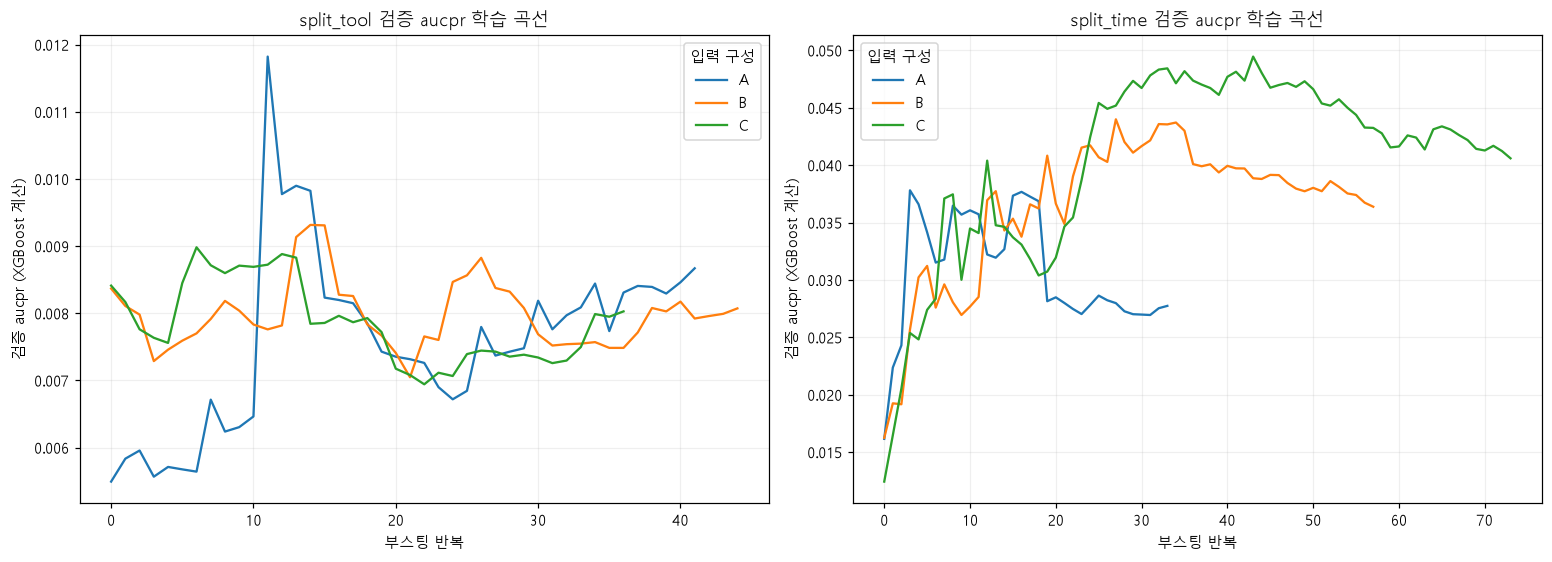

학습 곡선의 XGBoost aucpr와 최종 표의 sklearn Average Precision은 계산 정의가 달라 정확히 같은 숫자를 기대하지 않습니다. 보고서의 PR-AUC는 Average Precision(AP)로 통일했습니다.

In [2]:
from src.train_xgboost import train
for scheme in ("split_tool","split_time"):
    train(scheme,600)
    rows=[r for r in objects if r["scheme"]==scheme and r["horizon"]==600 and r["name"] in ("XGB_A","XGB_B","XGB_C")]
    display(pd.DataFrame([{ "모델":r["name"],"학습 가중치":r["details"]["parameters"]["scale_pos_weight"],"최적 반복":r["details"]["best_iteration"],"검증 임계값":r["threshold"],"검증 AP":r["metrics"]["validation"]["pr_auc_ap"],"평가 AP":r["metrics"]["evaluation"]["pr_auc_ap"],"평가 F1":r["metrics"]["evaluation"]["f1"]} for r in rows]))
fig,axes=plt.subplots(1,2,figsize=(14,5),layout="constrained")
for ax,scheme in zip(axes,("split_tool","split_time")):
    for config in ("A","B","C"):
        curve=read_json(OUT/"experiments"/f"{scheme}_h600"/("XGB_"+config)/"learning_curve.json")
        values=curve["validation_0"]["aucpr"]
        ax.plot(values,label=config)
    ax.set(title=f"{scheme} 검증 aucpr 학습 곡선",xlabel="부스팅 반복",ylabel="검증 aucpr (XGBoost 계산)");ax.legend(title="입력 구성");ax.grid(alpha=.2)
plots.save(fig,"xgboost_learning_curves")
display(Markdown("학습 곡선의 XGBoost aucpr와 최종 표의 sklearn Average Precision은 계산 정의가 달라 정확히 같은 숫자를 기대하지 않습니다. 보고서의 PR-AUC는 Average Precision(AP)로 통일했습니다."))

## Tool·Lot·절대 시각·사용량의 별도 진단

주 실험 C에 Tool, time, Lot, 사용량(runnum과 사용량 카운터 3개), 전체를 각각 추가한 XGBoost 10개를 별도로 실행했습니다. 원본을 청크로 읽고 동일 시각의 현재 정보만 연결했습니다. 식별자 인코더는 학습에서만 적합하고 새 범주는 -1로 처리합니다. 수치 결측은 XGBoost 기본 처리입니다. 이 진단 모델은 주 실험의 최종 구성 선정에서 제외했습니다.

장비 홀드아웃의 Tool 범주는 평가에서 모두 새로운 값이므로 식별자 효과를 일반화 가능한 장비 정보로 해석할 수 없습니다. 단일 시드의 별도 적합이므로 효과 차이에 모델 변동성도 포함됩니다. 절대 시각·Lot·사용량의 개선은 시간 위치/생산 이력 기억일 수 있으며 고장 전조의 증거가 아닙니다.

In [3]:
diagnostics=metrics[(metrics.horizon==600)&metrics.identity_diagnostic&(metrics.split=="evaluation")]
display(diagnostics[["scheme","name","precision","recall","f1","pr_auc_ap","roc_auc","event_recall"]])
display(pd.DataFrame([{ "분할":r["scheme"],"모델":r["name"],**r["details"].get("unknown_category_fraction",{})} for r in objects if r["details"].get("identity_diagnostic_only")]))
display(Markdown("랭킹 AP가 높아져도 검증 임계값이 평가 구간으로 전달되지 않아 F1이 낮을 수 있습니다. 식별자 진단 결과를 보고 평가 임계값을 다시 조정하지 않았습니다. 주 실험의 특징 목록에는 이 변수들이 들어가지 않습니다."))

,scheme,name,precision,recall,f1,pr_auc_ap,roc_auc,event_recall
74,split_time,XGB_C_ID_All,0.200000,0.122105,0.151634,0.156948,0.627622,0.196429
77,split_time,XGB_C_ID_Lot,0.638298,0.126316,0.210896,0.240769,0.641063,0.303571
80,split_time,XGB_C_ID_Time,0.819048,0.181053,0.296552,0.199365,0.573345,0.250000
83,split_time,XGB_C_ID_Tool,0.692308,0.151579,0.248705,0.241459,0.639792,0.303571
86,split_time,XGB_C_ID_Usage,0.202381,0.071579,0.105754,0.122454,0.597560,0.125000
161,split_tool,XGB_C_ID_All,1.000000,0.002899,0.005780,0.376908,0.672010,0.022222
164,split_tool,XGB_C_ID_Lot,0.028462,0.214493,0.050255,0.019537,0.561813,0.333333
167,split_tool,XGB_C_ID_Time,1.000000,0.040580,0.077994,0.350511,0.737609,0.111111
170,split_tool,XGB_C_ID_Tool,0.292683,0.034783,0.062176,0.040296,0.679058,0.066667
173,split_tool,XGB_C_ID_Usage,0.015138,0.147826,0.027464,0.012282,0.430122,0.333333


,분할,모델,train_Tool,validation_Tool,evaluation_Tool,train_Lot,validation_Lot,evaluation_Lot
0,split_time,XGB_C_ID_All,0.0,0.0,0.0,0.0,0.568982,0.878437
1,split_time,XGB_C_ID_Lot,NaN,NaN,NaN,0.0,0.568982,0.878437
2,split_time,XGB_C_ID_Time,NaN,NaN,NaN,NaN,NaN,NaN
3,split_time,XGB_C_ID_Tool,0.0,0.0,0.0,NaN,NaN,NaN
4,split_time,XGB_C_ID_Usage,NaN,NaN,NaN,NaN,NaN,NaN
5,split_tool,XGB_C_ID_All,0.0,1.0,1.0,0.0,0.741095,0.268428
6,split_tool,XGB_C_ID_Lot,NaN,NaN,NaN,0.0,0.741095,0.268428
7,split_tool,XGB_C_ID_Time,NaN,NaN,NaN,NaN,NaN,NaN
8,split_tool,XGB_C_ID_Tool,0.0,1.0,1.0,NaN,NaN,NaN
9,split_tool,XGB_C_ID_Usage,NaN,NaN,NaN,NaN,NaN,NaN


랭킹 AP가 높아져도 검증 임계값이 평가 구간으로 전달되지 않아 F1이 낮을 수 있습니다. 식별자 진단 결과를 보고 평가 임계값을 다시 조정하지 않았습니다. 주 실험의 특징 목록에는 이 변수들이 들어가지 않습니다.

## 300·1800 확장 실험

600 본 실험이 실행·분할 검사를 통과한 뒤 같은 설정으로 확장했습니다. 예측 구간마다 학습 클래스 비율과 검증 임계값·Early Stopping을 따로 계산했으며, 평가 결과에 맞춰 설정을 조정하지 않았습니다.

In [4]:
print("본 실험 통과 기록:",read_json(OUT/"primary_gate.json"))
print("실행 상태:",read_json(OUT/"run_status.json"))
display(metrics[(metrics.split=="evaluation")&(~metrics.identity_diagnostic)][["scheme","horizon","name","precision","recall","f1","pr_auc_ap","event_recall"]].sort_values(["horizon","scheme","name"]))

본 실험 통과 기록: {'horizon': 600, 'experiments': 16, 'passed': True, 'rule': '실행 오류 없음·평가 양성 존재·고정 분할; 평가 성능으로 설정을 조정하지 않음'}
실행 상태: {'experiments': 48, 'primary_completed': True, 'extensions_completed': True}


,scheme,horizon,name,precision,recall,f1,pr_auc_ap,event_recall
26,split_time,300,Dummy,NaN,0.000000,0.000000,0.018128,0.000000
29,split_time,300,Pressure,NaN,0.000000,0.000000,0.160688,0.000000
32,split_time,300,RF_A,1.000000,0.084291,0.155477,0.243807,0.107143
35,split_time,300,RF_B,0.506329,0.153257,0.235294,0.174491,0.196429
38,split_time,300,RF_C,0.434783,0.153257,0.226629,0.164026,0.214286
41,split_time,300,XGB_A,1.000000,0.076628,0.142349,0.230858,0.071429
44,split_time,300,XGB_B,0.483516,0.168582,0.250000,0.165254,0.375000
47,split_time,300,XGB_C,0.531646,0.160920,0.247059,0.179889,0.321429
113,split_tool,300,Dummy,NaN,0.000000,0.000000,0.004789,0.000000
116,split_tool,300,Pressure,0.007437,0.354167,0.014569,0.006684,0.377778
